In [1]:
def costo_entrada(modelo, tokens):
    """Costo en USD de una solicitud con `tokens` tokens de entrada al modelo de ChatGPT `modelo`."""
    
    tarifas = {
        'gpt-6-astra': {'short': 10.00, 'long': 20.00},
        'gpt-6-sol':   {'short': 2.00,  'long': 4.00},
        'gpt-6-luna':  {'short': 0.10,  'long': 0.20},
    }

    umbral = 272_000
    max_tokens = 1_050_000

    if modelo not in tarifas:
        raise ValueError('Modelo no reconocido')
        
    if tokens < 0 or tokens > max_tokens:
        raise ValueError('Número de tokens fuera del límite permitido')
        
    contexto = 'long' if tokens > umbral else 'short'
    precio_millon = tarifas[modelo][contexto]
    
    return tokens * precio_millon / 1000000

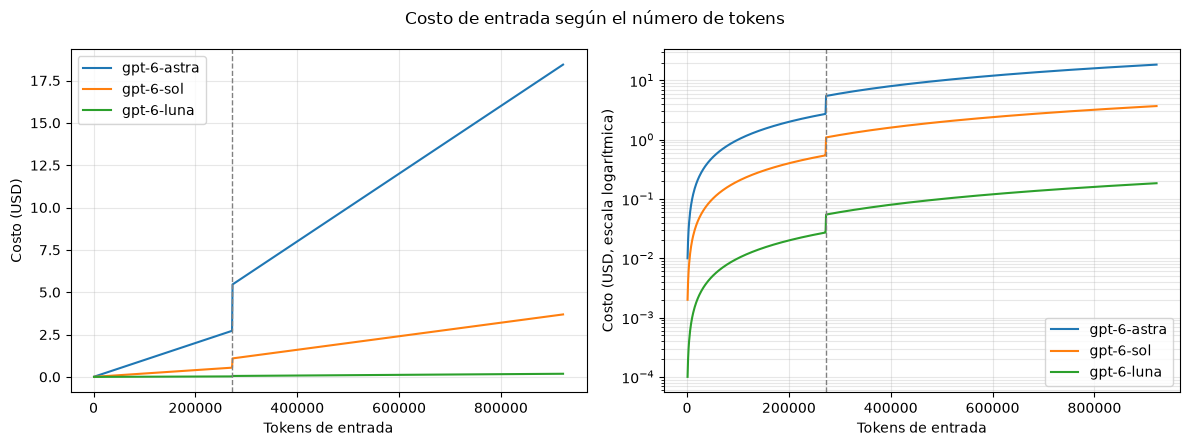

In [3]:
import matplotlib.pyplot as plt

def graficar_costos(tokens, costos_por_modelo, archivo="costos_api.png"):
    """Dibuja el costo de entrada frente al número de tokens.

    tokens: lista de enteros (eje x).
    costos_por_modelo: diccionario modelo -> lista de costos en USD, uno por valor de tokens.
    """
    fig, (lineal, logaritmica) = plt.subplots(1, 2, figsize=(12, 4.5))
    for modelo, costos in costos_por_modelo.items():
        lineal.plot(tokens, costos, label=modelo)
        logaritmica.plot(tokens, costos, label=modelo)
    for ax in (lineal, logaritmica):
        ax.axvline(272_000, color="gray", linestyle="--", linewidth=1)
        ax.set_xlabel("Tokens de entrada")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend()
    lineal.set_ylabel("Costo (USD)")
    logaritmica.set_ylabel("Costo (USD, escala logarítmica)")
    logaritmica.set_yscale("log")
    fig.suptitle("Costo de entrada según el número de tokens")
    fig.tight_layout()
    fig.savefig(archivo, dpi=150)
    plt.show()

modelos = ["gpt-6-astra", "gpt-6-sol", "gpt-6-luna"]
tokens = list(range(1_000, 922_001, 1_000))
costos = {m: [costo_entrada(m, n) for n in tokens] for m in modelos}
graficar_costos(tokens, costos)
